# Análise dos resultados do benchmark (kpibench)

Carrega os artefatos gerados por `python -m kpibench demo` (ou por uma execução
real) em `outputs/<run>/` e monta visualizações para apoiar a leitura do
`report.md`: desempenho por KPI/modelo, custo x performance e notas do juiz.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

PROJECT_ROOT = Path.cwd().parent
OUTPUTS_DIR = PROJECT_ROOT / "outputs"

# Pega a execução mais recente automaticamente; troque por um path fixo se preferir.
RUN_DIR = sorted(OUTPUTS_DIR.glob("demo_*"))[-1]
print(f"Usando execução: {RUN_DIR.name}")

Usando execução: demo_20261028_140614


In [2]:
metricas = pd.read_csv(RUN_DIR / "metricas_por_kpi_modelo.csv")
custos = pd.read_csv(RUN_DIR / "custos_latencia.csv")
roteamento = pd.read_csv(RUN_DIR / "recomendacao_roteamento.csv")
judge = pd.read_csv(RUN_DIR / "judge_scores.csv")

metricas.head()

,kpi,model,n,valid_rate,qwk,spearman,mae,exact_acc,within1_acc,primary_metric,...,pareto,perf_por_usd,judge_coverage,chrf,rouge_l,tfidf_cos,judge_score,macro_f1,accuracy,kappa
0,qualidade_resumo,gpt-5.4,120,1.000000,0.908784,0.893642,0.233333,0.800000,0.966667,qwk,...,True,0.124990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,qualidade_resumo,producao_atual,120,1.000000,0.895613,0.884125,0.383333,0.616667,1.000000,qwk,...,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,qualidade_resumo,claude-sonnet-5-5,120,1.000000,0.892216,0.886111,0.275000,0.775000,0.950000,qwk,...,True,0.339347,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,qualidade_resumo,gpt-5.4-mini,120,1.000000,0.874477,0.890759,0.333333,0.708333,0.958333,qwk,...,True,0.428345,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,qualidade_resumo,claude-haiku-5-5,120,0.983333,0.802395,0.819166,0.433333,0.683333,0.908333,qwk,...,True,6.765891,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1. Recomendação de roteamento por KPI

Resumo direto de `recomendacao_roteamento.csv`: modelo recomendado, custo
projetado e economia em relação ao melhor desempenho bruto.

In [3]:
cols = [
    "display", "recomendado", "perf_recomendado", "usd_mes_recomendado",
    "melhor", "perf_melhor", "economia_vs_melhor_pct",
]
roteamento[cols].sort_values("display")

,display,recomendado,perf_recomendado,usd_mes_recomendado,melhor,perf_melhor,economia_vs_melhor_pct
1,CSAT (inferido),claude-haiku-5-5,0.876582,65.577917,claude-haiku-5-5,0.876582,0.0
8,Clareza das informações,claude-sonnet-5-5,0.929956,1395.975000,claude-sonnet-5-5,0.929956,0.0
7,Empatia,gpt-5.4,0.902027,4090.729167,gpt-5.4,0.902027,0.0
6,First call resolution,claude-sonnet-5-5,0.846765,1475.516667,claude-sonnet-5-5,0.846765,0.0
9,ODC,claude-sonnet-5-5,0.933695,1462.391667,claude-sonnet-5-5,0.933695,0.0
0,Qualidade do resumo,gpt-5.4,0.908784,7270.833333,gpt-5.4,0.908784,0.0
5,Razão da ligação,gpt-5.4,0.990370,4370.479167,gpt-5.4,0.990370,0.0
2,Razão do CSAT,claude-haiku-5-5,0.887500,60.680000,claude-haiku-5-5,0.887500,0.0
3,Solicitação resolvida,gpt-5.4,0.908661,3957.104167,gpt-5.4,0.908661,0.0
4,Solver reasoning,claude-sonnet-5-5,0.891667,1399.391667,claude-sonnet-5-5,0.891667,0.0


## 2. Performance por modelo, para cada KPI

Usa `primary` (métrica primária de cada KPI, já escolhida pelo pipeline) para
comparar os modelos lado a lado.

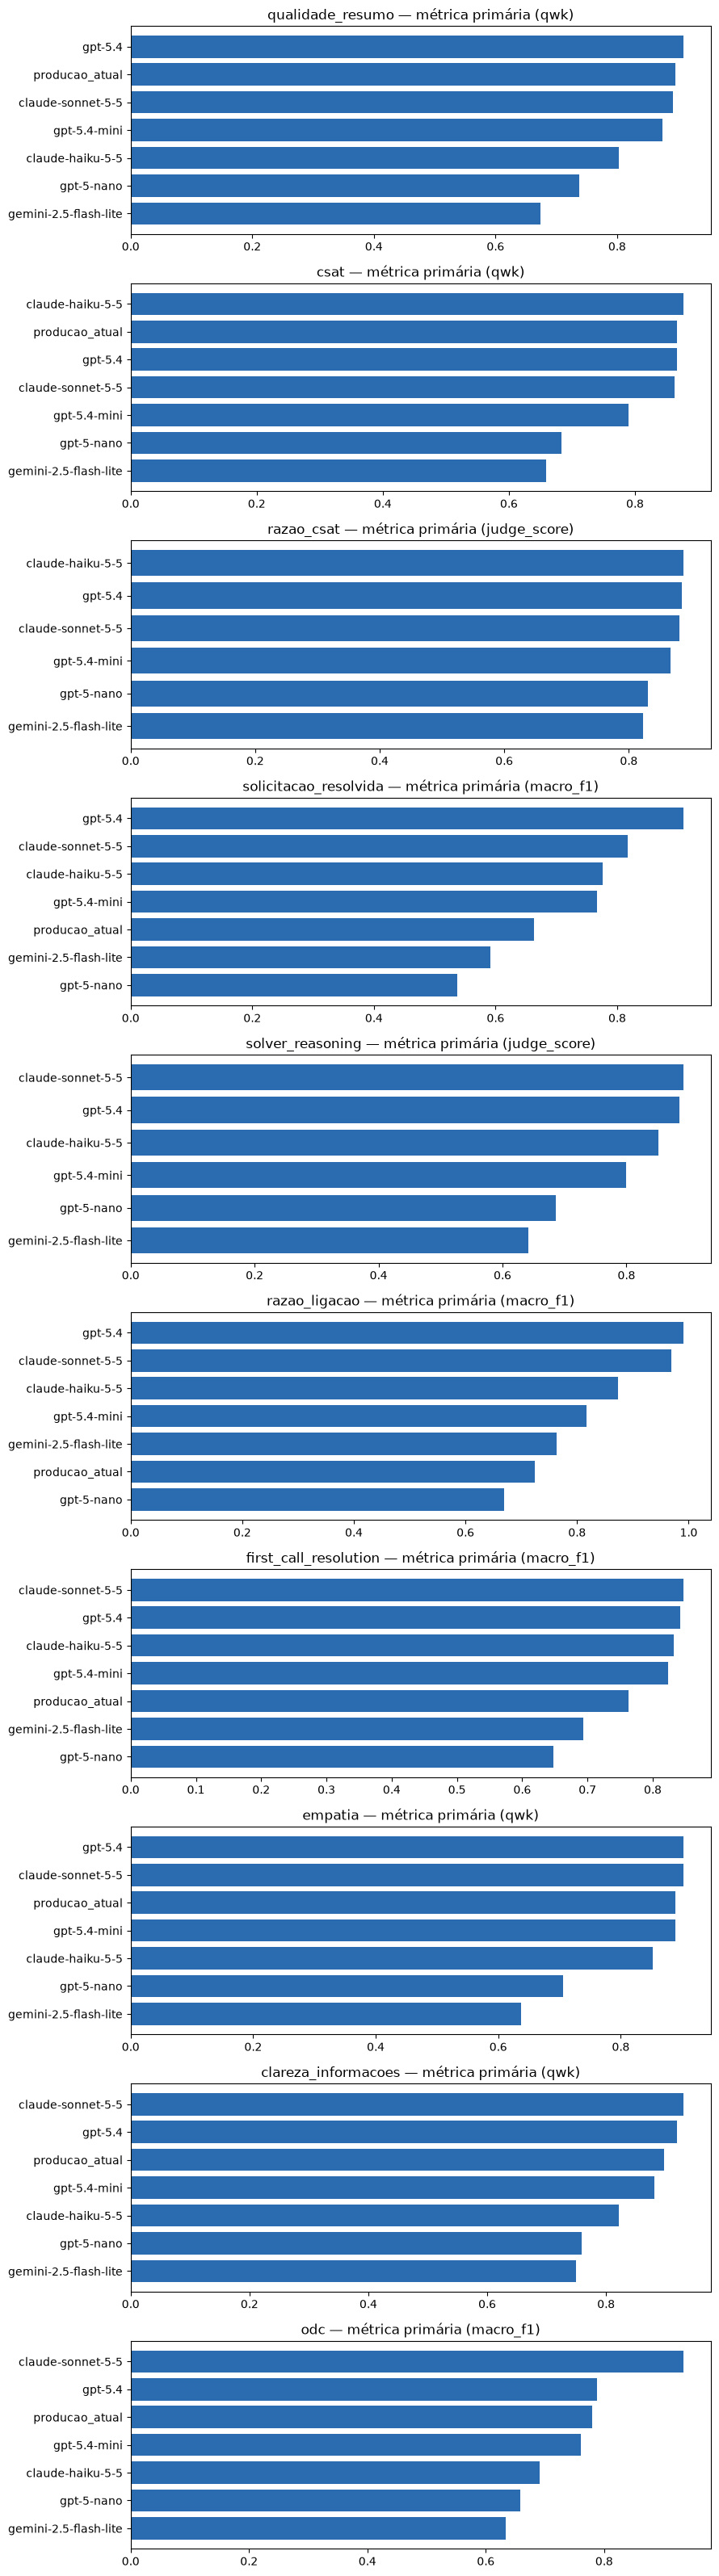

In [4]:
kpis = metricas["kpi"].unique()
fig, axes = plt.subplots(len(kpis), 1, figsize=(9, 3.2 * len(kpis)))
if len(kpis) == 1:
    axes = [axes]

for ax, kpi in zip(axes, kpis):
    sub = metricas[metricas["kpi"] == kpi].sort_values("primary", ascending=False)
    ax.barh(sub["model"], sub["primary"], color="#2b6cb0")
    ax.set_title(f"{kpi} — métrica primária ({sub['primary_metric'].iloc[0]})")
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

## 3. Custo x performance (Pareto)

Cada ponto é um modelo em um KPI: eixo X = custo mensal projetado, eixo Y =
métrica primária. Pontos marcados como `pareto=True` são não-dominados (nenhum
outro modelo é ao mesmo tempo mais barato e melhor).

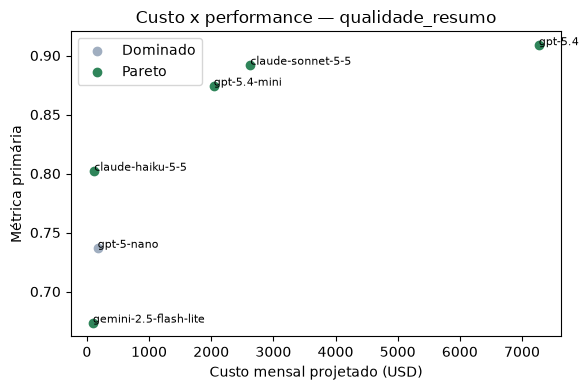

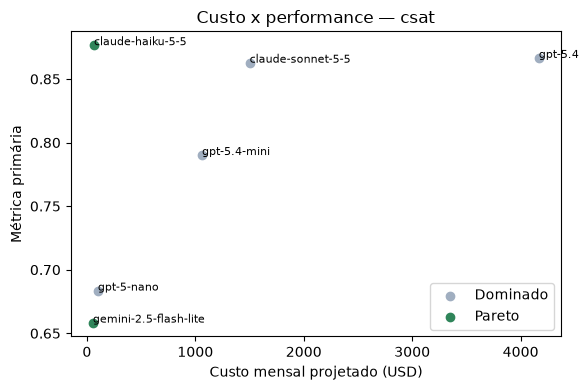

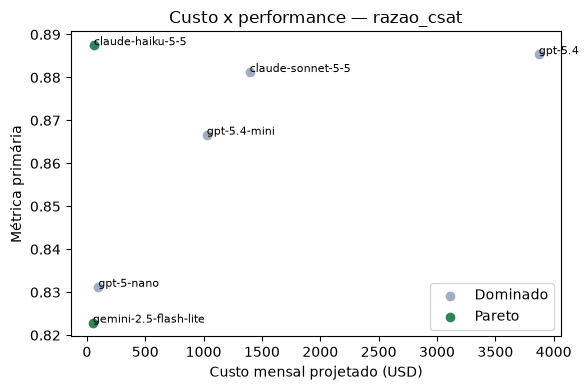

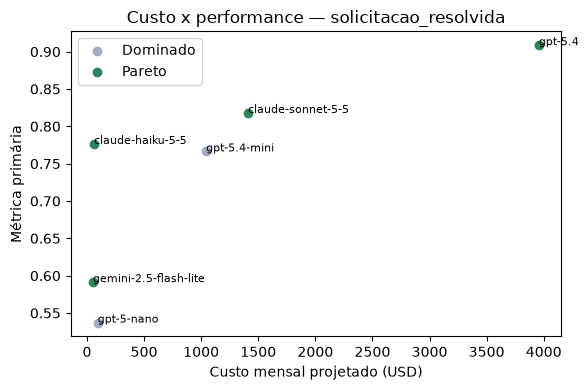

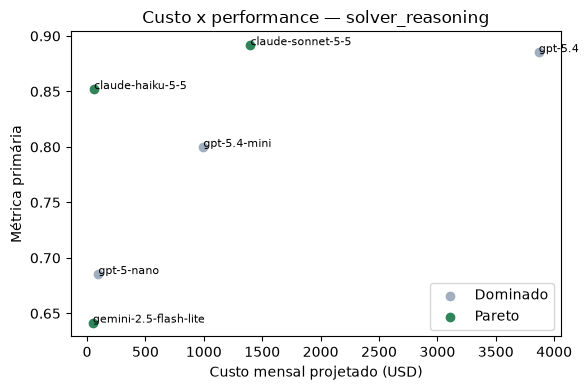

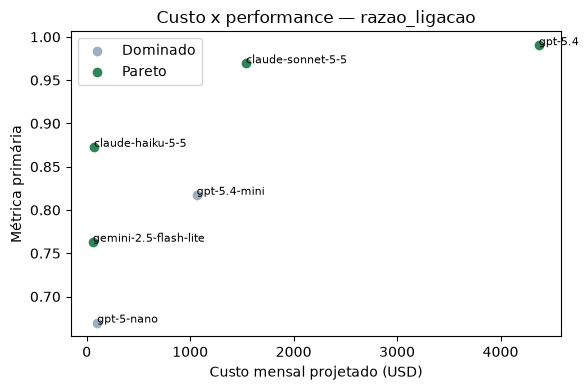

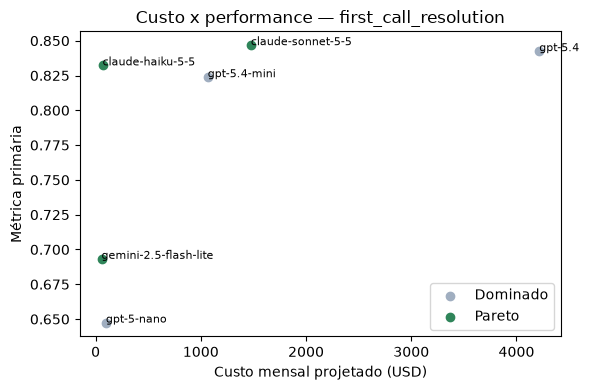

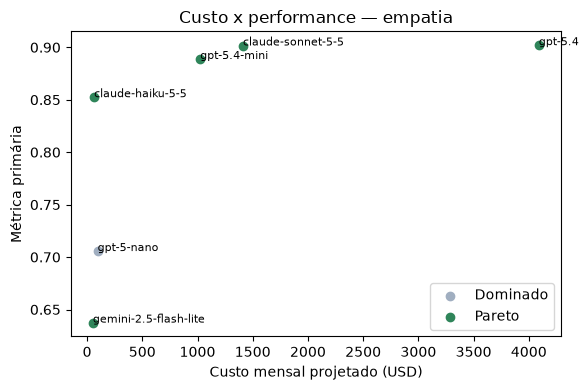

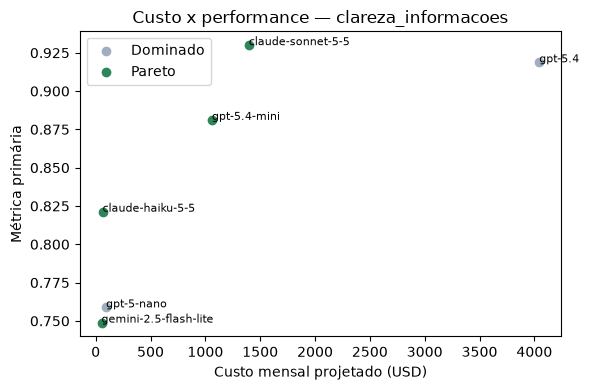

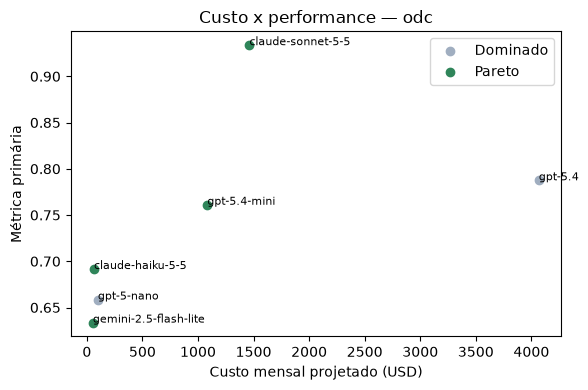

In [5]:
for kpi in kpis:
    sub = metricas[(metricas["kpi"] == kpi) & metricas["proj_usd_month"].notna()]
    if sub.empty:
        continue
    fig, ax = plt.subplots(figsize=(6, 4))
    for pareto, grp in sub.groupby("pareto"):
        ax.scatter(grp["proj_usd_month"], grp["primary"],
                   label="Pareto" if pareto else "Dominado",
                   color="#2f855a" if pareto else "#a0aec0")
    for _, row in sub.iterrows():
        ax.annotate(row["model"], (row["proj_usd_month"], row["primary"]), fontsize=8)
    ax.set_xlabel("Custo mensal projetado (USD)")
    ax.set_ylabel("Métrica primária")
    ax.set_title(f"Custo x performance — {kpi}")
    ax.legend()
    plt.tight_layout()
    plt.show()

## 4. Notas do juiz (judge_scores.csv)

Distribuição das notas do juiz por modelo, para os KPIs avaliados por LLM
(ex.: `razao_csat`).

In [6]:
judge_avg = judge.groupby(["kpi", "model"])["judge_score"].mean().unstack("model")
judge_avg

model,claude-haiku-5-5,claude-sonnet-5-5,gemini-2.5-flash-lite,gpt-5-nano,gpt-5.4,gpt-5.4-mini
kpi,,,,,,
razao_csat,0.887500,0.881250,0.851293,0.852564,0.885417,0.881356
solver_reasoning,0.859244,0.891667,0.669565,0.715217,0.885417,0.806723


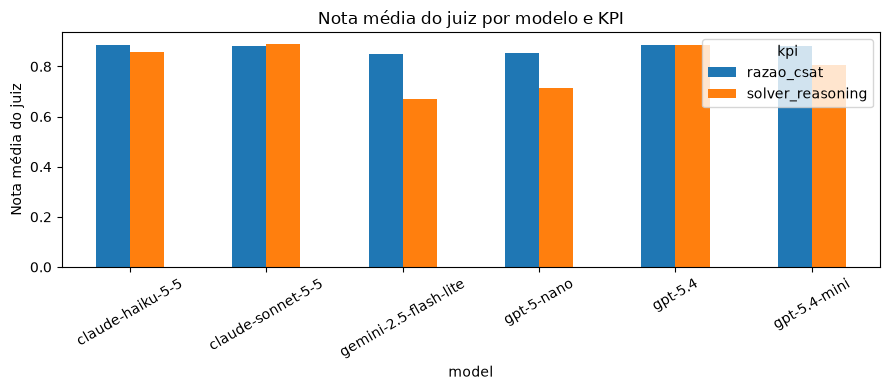

In [8]:
ax = judge_avg.T.plot(kind="bar", figsize=(9, 4))
ax.set_ylabel("Nota média do juiz")
ax.set_title("Nota média do juiz por modelo e KPI")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 5. Relatório completo (`report.md`)

In [7]:
report_path = RUN_DIR / "report.md"
display(Markdown(report_path.read_text(encoding="utf-8")))

# Benchmark de LLMs por KPI — demo
_Gerado em 2026-10-28 14:06 · 120 chamadas · 6 modelos · 10 KPIs avaliados_

> ⚠️ **RODADA SIMULADA (demo).** As saídas dos modelos foram geradas pelo provider mock a partir dos rótulos + ruído. Tokens vêm dos prompts reais e preços de `config/models.yaml`; métricas lexicais de resumo são calculadas de verdade. **Não use estes números para escolher modelo.**

## 1. Sumário executivo

Projeção para **1,000,000 chamadas/mês**, Batch API, cache hit 90% no prefixo estático (quando cacheável). Recomendado = modelo mais barato estatisticamente **não-inferior** ao melhor (IC 95% bootstrap pareado da diferença < margem do KPI). **Candidato econômico** = mais barato que não foi declarado inferior e cuja estimativa pontual está dentro da margem: é a hipótese de economia a confirmar com mais amostra antes de ir para produção.

| KPI                     | métrica     | recomendado       |   perf | IC 95%         |   US$/1k | melhor            |   perf melhor |   produção atual |
|:------------------------|:------------|:------------------|-------:|:---------------|---------:|:------------------|--------------:|-----------------:|
| Qualidade do resumo     | qwk         | gpt-5.4           |  0.909 | [0.856, 0.947] |    7.271 | gpt-5.4           |         0.909 |            0.896 |
| CSAT (inferido)         | qwk         | claude-haiku-5-5  |  0.877 | [0.816, 0.928] |    0.066 | claude-haiku-5-5  |         0.877 |            0.867 |
| Razão do CSAT           | judge_score | claude-haiku-5-5  |  0.887 | [0.854, 0.921] |    0.061 | claude-haiku-5-5  |         0.887 |          nan     |
| Solicitação resolvida   | macro_f1    | gpt-5.4           |  0.909 | [0.844, 0.962] |    3.957 | gpt-5.4           |         0.909 |            0.663 |
| Solver reasoning        | judge_score | claude-sonnet-5-5 |  0.892 | [0.840, 0.938] |    1.399 | claude-sonnet-5-5 |         0.892 |          nan     |
| Razão da ligação        | macro_f1    | gpt-5.4           |  0.990 | [0.966, 1.000] |    4.370 | gpt-5.4           |         0.990 |            0.724 |
| First call resolution   | macro_f1    | claude-sonnet-5-5 |  0.847 | [0.781, 0.909] |    1.476 | claude-sonnet-5-5 |         0.847 |            0.763 |
| Empatia                 | qwk         | gpt-5.4           |  0.902 | [0.846, 0.947] |    4.091 | gpt-5.4           |         0.902 |            0.889 |
| Clareza das informações | qwk         | claude-sonnet-5-5 |  0.930 | [0.891, 0.963] |    1.396 | claude-sonnet-5-5 |         0.930 |            0.898 |
| ODC                     | macro_f1    | claude-sonnet-5-5 |  0.934 | [0.871, 0.981] |    1.462 | claude-sonnet-5-5 |         0.934 |            0.779 |

**Candidatos econômicos a validar** (não declarados inferiores; ponto dentro da margem):

| KPI                     | candidato         | decisão      |   perf |   US$/1k |   economia vs recomendado % |   comparações inconclusivas |
|:------------------------|:------------------|:-------------|-------:|---------:|----------------------------:|----------------------------:|
| Qualidade do resumo     | gpt-5.4-mini      | inconclusivo |  0.874 |    2.042 |                      71.922 |                           4 |
| CSAT (inferido)         | claude-haiku-5-5  | referencia   |  0.877 |    0.066 |                       0.000 |                           4 |
| Razão do CSAT           | claude-haiku-5-5  | referencia   |  0.887 |    0.061 |                       0.000 |                           4 |
| Solicitação resolvida   | gpt-5.4           | referencia   |  0.909 |    3.957 |                       0.000 |                           2 |
| Solver reasoning        | claude-haiku-5-5  | inconclusivo |  0.852 |    0.061 |                      95.657 |                           3 |
| Razão da ligação        | claude-sonnet-5-5 | inconclusivo |  0.969 |    1.541 |                      64.752 |                           1 |
| First call resolution   | claude-haiku-5-5  | inconclusivo |  0.832 |    0.066 |                      95.524 |                           4 |
| Empatia                 | claude-haiku-5-5  | inconclusivo |  0.852 |    0.064 |                      98.443 |                           4 |
| Clareza das informações | gpt-5.4-mini      | inconclusivo |  0.881 |    1.060 |                      24.052 |                           4 |
| ODC                     | claude-sonnet-5-5 | referencia   |  0.934 |    1.462 |                       0.000 |                           0 |

**Planos de custo mensal** (o roteamento por KPI vs. um único modelo para tudo):

| plano                         | custo/mês     | KPIs não-inferiores   |   perf. média |
|:------------------------------|:--------------|:----------------------|--------------:|
| so_gemini-2.5-flash-lite      | US$ 582.56    | 0/10                  |         0.686 |
| so_claude-haiku-5-5           | US$ 693.68    | 2/10                  |         0.827 |
| so_gpt-5-nano                 | US$ 1,054.65  | 0/10                  |         0.691 |
| roteado_economico (a validar) | US$ 10,378.52 | 4/10                  |         0.887 |
| so_gpt-5.4-mini               | US$ 11,468.50 | 0/10                  |         0.827 |
| so_claude-sonnet-5-5          | US$ 15,621.49 | 4/10                  |         0.893 |
| roteado_por_kpi (conservador) | US$ 25,548.68 | 10/10                 |         0.908 |
| so_gpt-5.4                    | US$ 43,926.83 | 5/10                  |         0.890 |

> **30 comparações inconclusivas**: o IC da diferença cruza a margem. Com n=120, a amostra não separa modelos próximos. Ver seção 6 para o tamanho de amostra.

![Pareto](pareto_por_kpi.png)

## 2. Desenho do experimento

- **Prompt único por KPI**: o mesmo template (`prompts/kpis/<kpi>.md`) é renderizado para todos os modelos; só muda o cliente. Hash do template registrado em cada predição.
- **Parâmetros fixos por modelo** (`config/models.yaml`): temperatura 0 quando suportada; modelos de raciocínio com `reasoning_effort` declarado. Saída JSON estrita.
- **Saídas inválidas** (JSON quebrado, rótulo fora da taxonomia, nota fora da escala): política `pessimistic` — contam como erro, não são descartadas.
- **Métricas primárias**: ordinais → QWK (kappa quadrático); categóricos → macro-F1; texto livre → nota do LLM-juiz normalizada 0–1 (juiz: `claude-opus-5-5`), com chrF++/ROUGE-L como secundárias.
- **Estatística**: bootstrap não-paramétrico pareado, 1000 reamostragens, IC 95%.

| KPI | template | hash |
|---|---|---|
| qualidade_resumo | `prompts/kpis/qualidade_resumo.md` | `4018515aee40` |
| csat | `prompts/kpis/csat.md` | `cf43fe5dd4bf` |
| razao_csat | `prompts/kpis/razao_csat.md` | `cb5d634edb18` |
| solicitacao_resolvida | `prompts/kpis/solicitacao_resolvida.md` | `a4ac5a109405` |
| solver_reasoning | `prompts/kpis/solver_reasoning.md` | `31e063e809fd` |
| razao_ligacao | `prompts/kpis/razao_ligacao.md` | `64ea9e701202` |
| first_call_resolution | `prompts/kpis/first_call_resolution.md` | `4891976a210a` |
| empatia | `prompts/kpis/empatia.md` | `f47b8e4cba03` |
| clareza_informacoes | `prompts/kpis/clareza_informacoes.md` | `0d8b4f0187a9` |
| odc | `prompts/kpis/odc.md` | `6a14957e229a` |

## 3. Resultados por KPI

![Heatmap](heatmap_kpi_modelo.png)

### Qualidade do resumo (`qualidade_resumo` · ordinal · n=120 · margem NI=0.05)

| model                 |   qwk |   ci_low |   ci_high |   spearman |   mae |   exact_acc |   within1_acc |   valid_rate | decision     |   diff_ci_low |   diff_ci_high |   proj_usd_per_1k |   latency_p95_s | pareto   |
|:----------------------|------:|---------:|----------:|-----------:|------:|------------:|--------------:|-------------:|:-------------|--------------:|---------------:|------------------:|----------------:|:---------|
| gpt-5.4               | 0.909 |    0.856 |     0.947 |      0.894 | 0.233 |       0.800 |         0.967 |        1.000 | referencia   |         0.000 |          0.000 |             7.271 |          15.681 | True     |
| producao_atual        | 0.896 |    0.858 |     0.925 |      0.884 | 0.383 |       0.617 |         1.000 |        1.000 | inconclusivo |        -0.043 |          0.066 |           nan     |         nan     | False    |
| claude-sonnet-5-5     | 0.892 |    0.830 |     0.938 |      0.886 | 0.275 |       0.775 |         0.950 |        1.000 | inconclusivo |        -0.050 |          0.083 |             2.629 |           9.013 | True     |
| gpt-5.4-mini          | 0.874 |    0.818 |     0.918 |      0.891 | 0.333 |       0.708 |         0.958 |        1.000 | inconclusivo |        -0.033 |          0.102 |             2.042 |           7.990 | True     |
| claude-haiku-5-5      | 0.802 |    0.699 |     0.882 |      0.819 | 0.433 |       0.683 |         0.908 |        0.983 | inconclusivo |         0.016 |          0.214 |             0.119 |           3.448 | True     |
| gpt-5-nano            | 0.737 |    0.634 |     0.818 |      0.727 | 0.600 |       0.550 |         0.867 |        0.967 | inferior     |         0.074 |          0.277 |             0.174 |           6.694 | False    |
| gemini-2.5-flash-lite | 0.674 |    0.520 |     0.794 |      0.684 | 0.633 |       0.525 |         0.900 |        0.958 | inferior     |         0.099 |          0.392 |             0.097 |           3.493 | True     |

### CSAT (inferido) (`csat` · ordinal · n=120 · margem NI=0.05)

| model                 |   qwk |   ci_low |   ci_high |   spearman |   mae |   exact_acc |   within1_acc |   valid_rate | decision     |   diff_ci_low |   diff_ci_high |   proj_usd_per_1k |   latency_p95_s | pareto   |
|:----------------------|------:|---------:|----------:|-----------:|------:|------------:|--------------:|-------------:|:-------------|--------------:|---------------:|------------------:|----------------:|:---------|
| claude-haiku-5-5      | 0.877 |    0.816 |     0.928 |      0.889 | 0.242 |       0.800 |         0.958 |        0.992 | referencia   |         0.000 |          0.000 |             0.066 |           2.108 | True     |
| producao_atual        | 0.867 |    0.822 |     0.901 |      0.869 | 0.367 |       0.633 |         1.000 |        1.000 | inconclusivo |        -0.060 |          0.076 |           nan     |         nan     | False    |
| gpt-5.4               | 0.867 |    0.811 |     0.922 |      0.875 | 0.283 |       0.758 |         0.958 |        1.000 | inconclusivo |        -0.070 |          0.085 |             4.168 |           8.760 | False    |
| claude-sonnet-5-5     | 0.863 |    0.790 |     0.918 |      0.853 | 0.267 |       0.775 |         0.958 |        1.000 | inconclusivo |        -0.070 |          0.100 |             1.501 |           5.261 | False    |
| gpt-5.4-mini          | 0.790 |    0.668 |     0.883 |      0.795 | 0.350 |       0.733 |         0.933 |        0.983 | inconclusivo |        -0.025 |          0.221 |             1.062 |           4.732 | False    |
| gpt-5-nano            | 0.684 |    0.563 |     0.794 |      0.710 | 0.567 |       0.558 |         0.908 |        0.967 | inferior     |         0.070 |          0.328 |             0.102 |           3.654 | False    |
| gemini-2.5-flash-lite | 0.658 |    0.506 |     0.776 |      0.672 | 0.592 |       0.525 |         0.917 |        0.983 | inferior     |         0.092 |          0.358 |             0.056 |           1.686 | True     |

### Razão do CSAT (`razao_csat` · text · n=120 · margem NI=0.05)

| model                 |   judge_score |   ci_low |   ci_high |   chrf |   rouge_l |   tfidf_cos |   judge_coverage |   valid_rate | decision     |   diff_ci_low |   diff_ci_high |   proj_usd_per_1k |   latency_p95_s | pareto   |
|:----------------------|--------------:|---------:|----------:|-------:|----------:|------------:|-----------------:|-------------:|:-------------|--------------:|---------------:|------------------:|----------------:|:---------|
| claude-haiku-5-5      |         0.887 |    0.854 |     0.921 |  0.695 |     0.760 |       0.610 |            1.000 |        1.000 | referencia   |         0.000 |          0.000 |             0.061 |           2.118 | True     |
| gpt-5.4               |         0.885 |    0.854 |     0.917 |  0.679 |     0.756 |       0.606 |            1.000 |        1.000 | nao_inferior |        -0.044 |          0.046 |             3.873 |           9.107 | False    |
| claude-sonnet-5-5     |         0.881 |    0.842 |     0.917 |  0.673 |     0.758 |       0.598 |            1.000 |        1.000 | inconclusivo |        -0.042 |          0.054 |             1.395 |           4.858 | False    |
| gpt-5.4-mini          |         0.867 |    0.823 |     0.904 |  0.666 |     0.737 |       0.577 |            1.000 |        0.983 | inconclusivo |        -0.031 |          0.077 |             1.028 |           4.838 | False    |
| gpt-5-nano            |         0.831 |    0.785 |     0.871 |  0.627 |     0.674 |       0.513 |            1.000 |        0.975 | inconclusivo |         0.000 |          0.112 |             0.098 |           4.052 | False    |
| gemini-2.5-flash-lite |         0.823 |    0.779 |     0.865 |  0.633 |     0.689 |       0.516 |            1.000 |        0.967 | inconclusivo |         0.008 |          0.123 |             0.052 |           1.802 | True     |

### Solicitação resolvida (`solicitacao_resolvida` · categorical · n=120 · margem NI=0.03)

| model                 |   macro_f1 |   ci_low |   ci_high |   accuracy |   kappa |   valid_rate | decision     |   diff_ci_low |   diff_ci_high |   proj_usd_per_1k |   latency_p95_s | pareto   |
|:----------------------|-----------:|---------:|----------:|-----------:|--------:|-------------:|:-------------|--------------:|---------------:|------------------:|----------------:|:---------|
| gpt-5.4               |      0.909 |    0.844 |     0.962 |      0.917 |   0.861 |        1.000 | referencia   |         0.000 |          0.000 |             3.957 |           9.106 | True     |
| claude-sonnet-5-5     |      0.818 |    0.727 |     0.893 |      0.850 |   0.749 |        1.000 | inconclusivo |        -0.005 |          0.192 |             1.410 |           4.629 | True     |
| claude-haiku-5-5      |      0.776 |    0.683 |     0.861 |      0.800 |   0.676 |        0.975 | inconclusivo |         0.027 |          0.235 |             0.062 |           2.177 | True     |
| gpt-5.4-mini          |      0.766 |    0.674 |     0.848 |      0.783 |   0.649 |        0.975 | inferior     |         0.052 |          0.238 |             1.044 |           4.467 | False    |
| producao_atual        |      0.663 |    0.575 |     0.754 |      0.683 |   0.495 |        1.000 | inferior     |         0.143 |          0.347 |           nan     |         nan     | False    |
| gemini-2.5-flash-lite |      0.591 |    0.493 |     0.689 |      0.600 |   0.370 |        0.942 | inferior     |         0.212 |          0.429 |             0.052 |           1.777 | True     |
| gpt-5-nano            |      0.537 |    0.435 |     0.628 |      0.558 |   0.336 |        0.942 | inferior     |         0.273 |          0.476 |             0.094 |           3.535 | False    |

F1 por classe — `gpt-5.4`:

| label   |    f1 |   support |
|:--------|------:|----------:|
| sim     | 0.937 |        65 |
| parcial | 0.895 |        38 |
| nao     | 0.895 |        17 |

### Solver reasoning (`solver_reasoning` · text · n=120 · margem NI=0.05)

| model                 |   judge_score |   ci_low |   ci_high |   chrf |   rouge_l |   tfidf_cos |   judge_coverage |   valid_rate | decision     |   diff_ci_low |   diff_ci_high |   proj_usd_per_1k |   latency_p95_s | pareto   |
|:----------------------|--------------:|---------:|----------:|-------:|----------:|------------:|-----------------:|-------------:|:-------------|--------------:|---------------:|------------------:|----------------:|:---------|
| claude-sonnet-5-5     |         0.892 |    0.840 |     0.938 |  0.789 |     0.816 |       0.779 |            1.000 |        1.000 | referencia   |         0.000 |          0.000 |             1.399 |           4.782 | True     |
| gpt-5.4               |         0.885 |    0.831 |     0.931 |  0.793 |     0.815 |       0.781 |            1.000 |        1.000 | inconclusivo |        -0.065 |          0.075 |             3.869 |           9.076 | False    |
| claude-haiku-5-5      |         0.852 |    0.798 |     0.906 |  0.771 |     0.787 |       0.751 |            1.000 |        0.992 | inconclusivo |        -0.035 |          0.119 |             0.061 |           2.431 | True     |
| gpt-5.4-mini          |         0.800 |    0.738 |     0.858 |  0.721 |     0.733 |       0.693 |            1.000 |        0.992 | inconclusivo |         0.010 |          0.160 |             0.996 |           4.208 | False    |
| gpt-5-nano            |         0.685 |    0.615 |     0.752 |  0.651 |     0.650 |       0.587 |            1.000 |        0.958 | inferior     |         0.119 |          0.294 |             0.097 |           3.751 | False    |
| gemini-2.5-flash-lite |         0.642 |    0.573 |     0.715 |  0.603 |     0.599 |       0.531 |            1.000 |        0.958 | inferior     |         0.156 |          0.342 |             0.050 |           1.905 | True     |

### Razão da ligação (`razao_ligacao` · categorical · n=120 · margem NI=0.03)

| model                 |   macro_f1 |   ci_low |   ci_high |   accuracy |   kappa |   valid_rate | decision     |   diff_ci_low |   diff_ci_high |   proj_usd_per_1k |   latency_p95_s | pareto   |
|:----------------------|-----------:|---------:|----------:|-----------:|--------:|-------------:|:-------------|--------------:|---------------:|------------------:|----------------:|:---------|
| gpt-5.4               |      0.990 |    0.966 |     1.000 |      0.992 |   0.990 |        1.000 | referencia   |         0.000 |          0.000 |             4.370 |           9.417 | True     |
| claude-sonnet-5-5     |      0.969 |    0.918 |     1.000 |      0.975 |   0.970 |        1.000 | inconclusivo |        -0.001 |          0.064 |             1.541 |           4.771 | True     |
| claude-haiku-5-5      |      0.873 |    0.793 |     0.931 |      0.875 |   0.852 |        0.992 | inferior     |         0.066 |          0.187 |             0.070 |           2.230 | True     |
| gpt-5.4-mini          |      0.818 |    0.732 |     0.888 |      0.833 |   0.803 |        0.983 | inferior     |         0.098 |          0.262 |             1.063 |           5.045 | False    |
| gemini-2.5-flash-lite |      0.763 |    0.664 |     0.841 |      0.758 |   0.718 |        0.958 | inferior     |         0.145 |          0.330 |             0.060 |           1.831 | True     |
| producao_atual        |      0.724 |    0.622 |     0.805 |      0.742 |   0.693 |        1.000 | inferior     |         0.181 |          0.370 |           nan     |         nan     | False    |
| gpt-5-nano            |      0.670 |    0.563 |     0.748 |      0.675 |   0.621 |        0.967 | inferior     |         0.237 |          0.427 |             0.101 |           3.770 | False    |

F1 por classe — `gpt-5.4`:

| label                  |    f1 |   support |
|:-----------------------|------:|----------:|
| cobranca_indevida      | 1.000 |        26 |
| segunda_via_fatura     | 0.960 |        12 |
| cancelamento           | 0.963 |        14 |
| suporte_tecnico        | 1.000 |        31 |
| alteracao_plano        | 1.000 |         7 |
| portabilidade          | 1.000 |         9 |
| informacoes_gerais     | 1.000 |        10 |
| reclamacao_atendimento | 1.000 |        11 |

### First call resolution (`first_call_resolution` · categorical · n=120 · margem NI=0.03)

| model                 |   macro_f1 |   ci_low |   ci_high |   accuracy |   kappa |   valid_rate | decision     |   diff_ci_low |   diff_ci_high |   proj_usd_per_1k |   latency_p95_s | pareto   |
|:----------------------|-----------:|---------:|----------:|-----------:|--------:|-------------:|:-------------|--------------:|---------------:|------------------:|----------------:|:---------|
| claude-sonnet-5-5     |      0.847 |    0.781 |     0.909 |      0.808 |   0.646 |        1.000 | referencia   |         0.000 |          0.000 |             1.476 |           4.977 | True     |
| gpt-5.4               |      0.842 |    0.775 |     0.901 |      0.792 |   0.620 |        1.000 | inconclusivo |        -0.074 |          0.092 |             4.216 |          10.148 | False    |
| claude-haiku-5-5      |      0.832 |    0.759 |     0.884 |      0.775 |   0.601 |        1.000 | inconclusivo |        -0.063 |          0.106 |             0.066 |           2.220 | True     |
| gpt-5.4-mini          |      0.824 |    0.755 |     0.888 |      0.783 |   0.604 |        1.000 | inconclusivo |        -0.071 |          0.112 |             1.066 |           4.254 | False    |
| producao_atual        |      0.763 |    0.679 |     0.837 |      0.725 |   0.496 |        1.000 | inconclusivo |        -0.011 |          0.186 |           nan     |         nan     | False    |
| gemini-2.5-flash-lite |      0.693 |    0.603 |     0.766 |      0.625 |   0.369 |        0.975 | inferior     |         0.064 |          0.246 |             0.056 |           1.665 | True     |
| gpt-5-nano            |      0.647 |    0.556 |     0.727 |      0.600 |   0.308 |        0.983 | inferior     |         0.089 |          0.316 |             0.098 |           4.349 | False    |

F1 por classe — `claude-sonnet-5-5`:

| label         |    f1 |   support |
|:--------------|------:|----------:|
| sim           | 0.843 |        51 |
| nao           | 0.850 |        69 |
| indeterminado | 0.000 |         0 |

### Empatia (`empatia` · ordinal · n=120 · margem NI=0.05)

| model                 |   qwk |   ci_low |   ci_high |   spearman |   mae |   exact_acc |   within1_acc |   valid_rate | decision     |   diff_ci_low |   diff_ci_high |   proj_usd_per_1k |   latency_p95_s | pareto   |
|:----------------------|------:|---------:|----------:|-----------:|------:|------------:|--------------:|-------------:|:-------------|--------------:|---------------:|------------------:|----------------:|:---------|
| gpt-5.4               | 0.902 |    0.846 |     0.947 |      0.907 | 0.217 |       0.825 |         0.958 |        1.000 | referencia   |         0.000 |          0.000 |             4.091 |           9.563 | True     |
| claude-sonnet-5-5     | 0.902 |    0.848 |     0.946 |      0.918 | 0.208 |       0.833 |         0.958 |        1.000 | inconclusivo |        -0.070 |          0.073 |             1.412 |           4.936 | True     |
| producao_atual        | 0.889 |    0.846 |     0.920 |      0.885 | 0.342 |       0.658 |         1.000 |        1.000 | inconclusivo |        -0.041 |          0.070 |           nan     |         nan     | False    |
| gpt-5.4-mini          | 0.889 |    0.831 |     0.930 |      0.873 | 0.300 |       0.725 |         0.975 |        1.000 | inconclusivo |        -0.050 |          0.085 |             1.024 |           4.567 | True     |
| claude-haiku-5-5      | 0.852 |    0.766 |     0.917 |      0.863 | 0.283 |       0.792 |         0.933 |        0.992 | inconclusivo |        -0.038 |          0.144 |             0.064 |           1.994 | True     |
| gpt-5-nano            | 0.706 |    0.572 |     0.803 |      0.708 | 0.567 |       0.575 |         0.892 |        0.967 | inferior     |         0.088 |          0.329 |             0.096 |           4.109 | False    |
| gemini-2.5-flash-lite | 0.637 |    0.468 |     0.786 |      0.644 | 0.550 |       0.650 |         0.883 |        0.942 | inferior     |         0.114 |          0.447 |             0.053 |           1.873 | True     |

### Clareza das informações (`clareza_informacoes` · ordinal · n=120 · margem NI=0.05)

| model                 |   qwk |   ci_low |   ci_high |   spearman |   mae |   exact_acc |   within1_acc |   valid_rate | decision     |   diff_ci_low |   diff_ci_high |   proj_usd_per_1k |   latency_p95_s | pareto   |
|:----------------------|------:|---------:|----------:|-----------:|------:|------------:|--------------:|-------------:|:-------------|--------------:|---------------:|------------------:|----------------:|:---------|
| claude-sonnet-5-5     | 0.930 |    0.891 |     0.963 |      0.944 | 0.183 |       0.842 |         0.975 |        1.000 | referencia   |         0.000 |          0.000 |             1.396 |           4.830 | True     |
| gpt-5.4               | 0.919 |    0.874 |     0.952 |      0.915 | 0.233 |       0.783 |         0.983 |        1.000 | inconclusivo |        -0.035 |          0.061 |             4.045 |           9.138 | False    |
| producao_atual        | 0.898 |    0.864 |     0.927 |      0.896 | 0.342 |       0.658 |         1.000 |        1.000 | inconclusivo |        -0.008 |          0.071 |           nan     |         nan     | False    |
| gpt-5.4-mini          | 0.881 |    0.823 |     0.927 |      0.882 | 0.308 |       0.733 |         0.958 |        1.000 | inconclusivo |        -0.008 |          0.111 |             1.060 |           5.329 | True     |
| claude-haiku-5-5      | 0.821 |    0.723 |     0.901 |      0.828 | 0.375 |       0.692 |         0.950 |        0.992 | inconclusivo |         0.022 |          0.214 |             0.062 |           2.105 | True     |
| gpt-5-nano            | 0.759 |    0.654 |     0.839 |      0.758 | 0.525 |       0.592 |         0.900 |        0.967 | inferior     |         0.085 |          0.278 |             0.095 |           4.161 | False    |
| gemini-2.5-flash-lite | 0.749 |    0.632 |     0.842 |      0.749 | 0.508 |       0.633 |         0.892 |        0.967 | inferior     |         0.088 |          0.293 |             0.053 |           1.793 | True     |

### ODC (`odc` · categorical · n=120 · margem NI=0.03)

| model                 |   macro_f1 |   ci_low |   ci_high |   accuracy |   kappa |   valid_rate | decision   |   diff_ci_low |   diff_ci_high |   proj_usd_per_1k |   latency_p95_s | pareto   |
|:----------------------|-----------:|---------:|----------:|-----------:|--------:|-------------:|:-----------|--------------:|---------------:|------------------:|----------------:|:---------|
| claude-sonnet-5-5     |      0.934 |    0.871 |     0.981 |      0.950 |   0.933 |        1.000 | referencia |         0.000 |          0.000 |             1.462 |           4.795 | True     |
| gpt-5.4               |      0.788 |    0.684 |     0.862 |      0.833 |   0.782 |        1.000 | inferior   |         0.058 |          0.249 |             4.067 |           8.614 | False    |
| producao_atual        |      0.779 |    0.675 |     0.855 |      0.800 |   0.744 |        1.000 | inferior   |         0.060 |          0.271 |           nan     |         nan     | False    |
| gpt-5.4-mini          |      0.761 |    0.658 |     0.842 |      0.817 |   0.762 |        1.000 | inferior   |         0.083 |          0.285 |             1.084 |           4.819 | True     |
| claude-haiku-5-5      |      0.692 |    0.576 |     0.788 |      0.750 |   0.677 |        0.992 | inferior   |         0.136 |          0.357 |             0.064 |           2.065 | True     |
| gpt-5-nano            |      0.659 |    0.554 |     0.738 |      0.675 |   0.597 |        0.950 | inferior   |         0.188 |          0.381 |             0.099 |           3.898 | False    |
| gemini-2.5-flash-lite |      0.634 |    0.514 |     0.723 |      0.675 |   0.588 |        0.933 | inferior   |         0.194 |          0.431 |             0.054 |           1.797 | True     |

F1 por classe — `claude-sonnet-5-5`:

| label                  |    f1 |   support |
|:-----------------------|------:|----------:|
| resolvido_no_contato   | 0.970 |        52 |
| protocolo_aberto       | 0.936 |        23 |
| encaminhado_tecnico    | 0.968 |        15 |
| retencao_aplicada      | 1.000 |         6 |
| cancelamento_efetivado | 0.714 |         7 |
| transferido            | 1.000 |         8 |
| sem_solucao            | 0.947 |         9 |

## 4. Qualidade do resumo — métricas modernas vs. eficientes

Cada métrica é correlacionada com a nota humana (`gt_qualidade_resumo`). `auc_detecta_ruim` mede a capacidade de separar resumos com nota ≤ 2 (uso de triagem). Custos: métricas de CPU são ~US$0; modelos locais têm custo de infra (ver ms/item); LLM-juiz tem custo de API medido.

| metric                                | grupo     | familia            | referencia   |   spearman |   spearman_ci_low |   spearman_ci_high |   kendall_tau_b |   auc_detecta_ruim |   cobertura |   ms_por_item |   usd_por_1k | status                                                               |
|:--------------------------------------|:----------|:-------------------|:-------------|-----------:|------------------:|-------------------:|----------------:|-------------------:|------------:|--------------:|-------------:|:---------------------------------------------------------------------|
| geval[gpt-5.4]                        | moderna   | llm_juiz           | fonte        |      0.894 |             0.829 |              0.945 |           0.848 |              0.990 |       1.000 |     10588.425 |       14.542 | ok                                                                   |
| geval[gpt-5.4-mini]                   | moderna   | llm_juiz           | fonte        |      0.891 |             0.846 |              0.927 |           0.824 |              0.957 |       1.000 |      5355.649 |        4.083 | ok                                                                   |
| geval[claude-sonnet-5-5]              | moderna   | llm_juiz           | fonte        |      0.886 |             0.823 |              0.937 |           0.831 |              0.978 |       1.000 |      5710.524 |        5.258 | ok                                                                   |
| geval[claude-haiku-5-5]               | moderna   | llm_juiz           | fonte        |      0.865 |             0.811 |              0.911 |           0.786 |              0.935 |       0.983 |      2419.842 |        0.237 | ok                                                                   |
| geval[gemini-2.5-flash-lite]          | moderna   | llm_juiz           | fonte        |      0.807 |             0.738 |              0.866 |           0.716 |              0.924 |       0.958 |      2158.843 |        0.194 | ok                                                                   |
| geval[gpt-5-nano]                     | moderna   | llm_juiz           | fonte        |      0.779 |             0.683 |              0.849 |           0.689 |              0.917 |       0.967 |      4560.955 |        0.349 | ok                                                                   |
| numeric_consistency                   | eficiente | factual_heuristica | fonte        |      0.752 |             0.660 |              0.816 |           0.664 |              0.999 |       1.000 |         0.010 |        0.000 | ok                                                                   |
| claim_faithfulness[claude-sonnet-5-5] | moderna   | llm_juiz           | fonte        |      0.589 |             0.451 |              0.708 |           0.493 |              0.890 |       1.000 |      5800.714 |        4.395 | ok                                                                   |
| rougeL_f                              | eficiente | lexical            | referencia   |      0.488 |             0.341 |              0.621 |           0.370 |              0.739 |       1.000 |         0.321 |        0.000 | ok                                                                   |
| tfidf_cosine                          | eficiente | lexical            | referencia   |      0.471 |             0.331 |              0.609 |           0.357 |              0.768 |       1.000 |         0.176 |        0.000 | ok                                                                   |
| rouge1_f                              | eficiente | lexical            | referencia   |      0.460 |             0.295 |              0.603 |           0.352 |              0.631 |       1.000 |         0.049 |        0.000 | ok                                                                   |
| source_rouge2_precision               | eficiente | factual_heuristica | fonte        |      0.415 |             0.275 |              0.556 |           0.304 |              0.751 |       1.000 |         0.061 |        0.000 | ok                                                                   |
| novel_bigram_rate                     | eficiente | factual_heuristica | fonte        |      0.409 |             0.267 |              0.547 |           0.299 |              0.745 |       1.000 |         0.060 |        0.000 | ok                                                                   |
| rouge2_f                              | eficiente | lexical            | referencia   |      0.328 |             0.157 |              0.488 |           0.247 |              0.674 |       1.000 |         0.048 |        0.000 | ok                                                                   |
| bleu                                  | eficiente | lexical            | referencia   |      0.313 |             0.139 |              0.470 |           0.236 |              0.588 |       1.000 |         0.112 |        0.000 | ok                                                                   |
| chrf++                                | eficiente | lexical            | referencia   |      0.250 |             0.076 |              0.417 |           0.175 |              0.449 |       1.000 |         0.724 |        0.000 | ok                                                                   |
| bertscore_f1                          | moderna   | embedding          | referencia   |    nan     |           nan     |            nan     |         nan     |            nan     |     nan     |       nan     |        0.000 | pulada: ModuleNotFoundError: No module named 'bert_score'            |
| embedding_cosine                      | moderna   | embedding          | referencia   |    nan     |           nan     |            nan     |         nan     |            nan     |     nan     |       nan     |        0.000 | pulada: ModuleNotFoundError: No module named 'sentence_transformers' |
| summac_zs                             | moderna   | nli                | fonte        |    nan     |           nan     |            nan     |         nan     |            nan     |     nan     |       nan     |        0.000 | pulada: ModuleNotFoundError: No module named 'torch'                 |

![Meta-avaliação](meta_avaliacao_metricas_resumo.png)

**Leitura:** melhor eficiente = `numeric_consistency` (ρ=0.752); melhor moderna = `geval[gpt-5.4]` (ρ=0.894, US$ 14.54/1k medido, API síncrona). Ganho de concordância de +0.142 em ρ. Arquitetura sugerida: métrica eficiente como filtro de 100% do volume + juiz moderno em amostra/estratos sinalizados.

Métricas puladas nesta rodada (instale `.[neural]` e garanta acesso ao Hugging Face Hub):

- `bertscore_f1` — pulada: ModuleNotFoundError: No module named 'bert_score'
- `embedding_cosine` — pulada: ModuleNotFoundError: No module named 'sentence_transformers'
- `summac_zs` — pulada: ModuleNotFoundError: No module named 'torch'

## 5. Custo e latência

Médias por chamada de KPI (um KPI por chamada). `usd_mes_todos_kpis` = 10 chamadas por ligação.

| model                 | tier          |   tokens_entrada |   tokens_saida |   usd_1k_medido |   usd_1k_std |   usd_1k_batch |   usd_mes_todos_kpis |   lat_p50 |   lat_p95 |   erro | prefixo_cacheavel   |
|:----------------------|:--------------|-----------------:|---------------:|----------------:|-------------:|---------------:|---------------------:|----------:|----------:|-------:|:--------------------|
| gemini-2.5-flash-lite | economico     |         499.3867 |       166.4350 |          0.1165 |       0.1165 |         0.0583 |             582.5633 |    1.0829 |    3.4932 | 0.0417 | False               |
| claude-haiku-5-5      | economico     |         499.3867 |       177.5950 |          0.1387 |       0.1387 |         0.0694 |             693.6808 |    1.3049 |    3.4479 | 0.0092 | False               |
| gpt-5-nano            | economico     |         499.3867 |       464.9000 |          0.2109 |       0.2109 |         0.1055 |            1054.6467 |    2.3787 |    6.6939 | 0.0358 | False               |
| gpt-5.4-mini          | intermediario |         499.3867 |       426.4800 |          2.2937 |       2.2937 |         1.1469 |           11468.5000 |    2.8619 |    7.9903 | 0.0083 | False               |
| claude-sonnet-5-5     | premium       |         499.3867 |       212.5525 |          3.1243 |       3.1243 |         1.5621 |           15621.4917 |    3.0816 |    9.0129 | 0.0000 | False               |
| gpt-5.4               | premium       |         499.3867 |       502.4600 |          8.7854 |       8.7854 |         4.3927 |           43926.8333 |    5.6199 |   15.6814 | 0.0000 | False               |

> Nenhum system prompt atinge o mínimo cacheável (≈1.024 tokens): prompt caching não reduz custo neste desenho. Não vale inflar o prompt só para cachear — o ganho real está na Batch API.

Custo de avaliação desta rodada (juízes, não entra em produção): juiz de justificativas US$ 8.51, fidelidade por afirmações US$ 0.5273.

## 6. Limitações e ameaças à validade

- **Tamanho de amostra**: largura mediana do IC 95% = 0.135 com n=120. Para ICs com largura ≈ margem (0.05), n ≈ 881 (escala ~1/√n). Estratifique por motivo de ligação e desfecho.
- **Ruído do rótulo**: os rótulos validados também têm erro; meça a concordância entre auditores (kappa inter-anotador) — é o teto prático de qualquer modelo.
- **Viés do LLM-juiz**: juiz da mesma família que o candidato tende a favorecê-lo (self-preference). Calibre o juiz contra uma amostra com nota humana antes de confiar na métrica de texto.
- **KPIs a partir do resumo**: erros do resumo propagam para todos os KPIs. Um resumo ruim limita o teto de CSAT/FCR/ODC independentemente do modelo extrator.
- **Preços**: conferidos nas datas em `config/models.yaml` (algumas fontes são agregadores). Valide no contrato Azure/Anthropic/Google antes de orçar.
- **Deriva**: reavalie ao trocar versão de modelo, prompt (hash muda) ou perfil de chamadas.
